# Week 11 - Introduction to Modeling, part 2

# 1. Lesson - No lesson this week

# 2. Weekly graph question

In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer

The book names one of Vonnegut's rules as "keep it simple" and another as "have the guts to cut."  Here is some data from the previous week's lesson.  If you had to cut one of the two plots below, which would it be?  Which seems more interesting or important?  Explain.  (Should "amount of training data used" or "number of estimators" be on the x-axis.)

In [ ]:
np.random.seed(0)
num_points = 10000
feature_1a = np.random.random(size = num_points) * 3
feature_2a = np.random.random(size = num_points) * 3
feature_3a = np.random.random(size = num_points) * 3
train_target = (feature_1a - 2 * feature_2a) * feature_3a + np.random.normal(size = num_points)
feature_1b = np.random.random(size = num_points) * 3
feature_2b = np.random.random(size = num_points) * 3
feature_3b = np.random.random(size = num_points) * 3
test_target = (feature_1b - 2 * feature_2b) * feature_3b + np.random.normal(size = num_points)
train_df = pd.DataFrame({"f1": feature_1a, "f2": feature_2a, "f3": feature_3a})
test_df = pd.DataFrame({"f1": feature_1b, "f2": feature_2b, "f3": feature_3b})
rf = RandomForestRegressor()
rf.fit(train_df.values, train_target)

RandomForestRegressor()

In [ ]:
rmse_lst = list()
rf = RandomForestRegressor()
for x in range(round(num_points / 20), num_points, round(num_points / 20)):
    rf.fit(train_df.values[0:x,:], train_target[0:x])
    rmse_lst.append(root_mean_squared_error(rf.predict(test_df.values), test_target))

import matplotlib.pyplot as plt

Text(0, 0.5, 'Loss function')

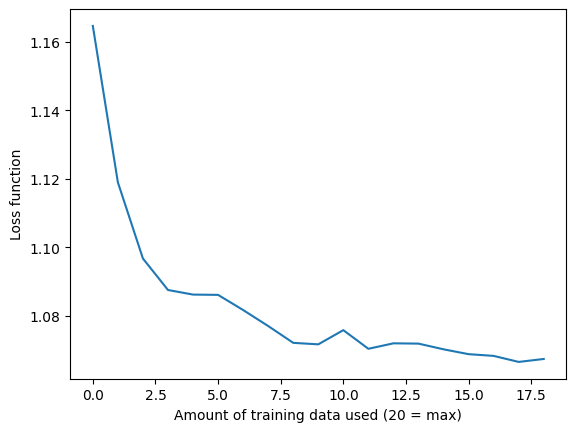

In [ ]:
plt.plot(rmse_lst)
plt.xlabel("Amount of training data used (20 = max)")
plt.ylabel("Loss function")

In [ ]:
num_trees_lst = list()
for n_estimators in range(1, 100, 3):
    rf = RandomForestRegressor(n_estimators = n_estimators)
    rf.fit(train_df.values, train_target)
    num_trees_lst.append(root_mean_squared_error(rf.predict(test_df.values), test_target))

Text(0, 0.5, 'Loss function')

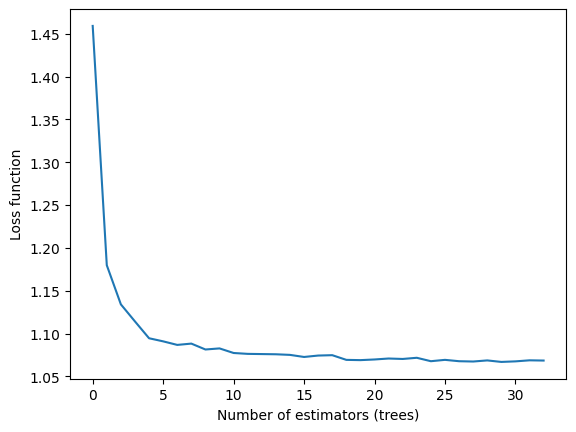

In [ ]:
plt.plot(num_trees_lst)
plt.xlabel("Number of estimators (trees)")
plt.ylabel("Loss function")

I would keep the first graph about the amount of training data and remove the second graph about the number of trees. Both graphs show that the error gets smaller at first and then starts to level off. I think the first graph is more useful because it shows how adding more training data can help the model. Each graph should have the variable being changed on the x-axis: training data in the first graph and number of trees in the second.

# 3. Working on your chosen project datasets this semester

This week, you will do the same types of exercises as last week, but you should use your chosen datasets that someone in your class found last semester. (They likely will not be the particular datasets that you found yourself.)

Here are some types of analysis you can do:

* Implement a random forest model.
* Perform cross-validation.
* Tune hyperparameters.
* Evaluate a performance metric.

If you like, you can try other types of models, too (beyond linear regression and random forest) although you will have many opportunities to do that next semester.

In [ ]:
data = pd.read_csv("ecuador_macro_long(2).csv")

ecuador = data.pivot(index="year", columns="indicator_name", values="value")

ecuador = ecuador[["household_consumption_growth_pct",
                   "inflation_cpi_annual_pct",
                   "unemployment_pct",
                   "gdp_growth_annual_pct"]].dropna()

print("Years:", ecuador.index.min(), "to", ecuador.index.max())
print("Number of years:", len(ecuador))
ecuador.head()

Years: 1995 to 2025
Number of years: 31


indicator_name,household_consumption_growth_pct,inflation_cpi_annual_pct,unemployment_pct,gdp_growth_annual_pct
year,,,,
1995,3.9843,22.9341,4.408,2.2525
1996,1.2647,24.4115,4.422,1.7317
1997,5.9587,30.6576,4.424,4.3279
1998,6.8838,36.0984,4.389,3.2665
1999,-12.1964,52.2420,4.656,-4.7394


In [ ]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score, GridSearchCV
from sklearn.metrics import mean_absolute_error, r2_score

X = ecuador[["household_consumption_growth_pct",
             "inflation_cpi_annual_pct",
             "unemployment_pct"]]
y = ecuador["gdp_growth_annual_pct"]

X_train, X_test = X.iloc[:-6], X.iloc[-6:]
y_train, y_test = y.iloc[:-6], y.iloc[-6:]

model = RandomForestRegressor(n_estimators=50, random_state=42)
model.fit(X_train, y_train)

predictions = model.predict(X_test)
print("Test MAE:", round(mean_absolute_error(y_test, predictions), 2))
print("Test R2:", round(r2_score(y_test, predictions), 2))

Test MAE: 3.97
Test R2: 0.23


In [ ]:
cv = TimeSeriesSplit(n_splits=3)
cv_scores = cross_val_score(model, X_train, y_train, cv=cv,
                            scoring="neg_mean_absolute_error")
print("Average cross-validation MAE:", round(-cv_scores.mean(), 2))

Average cross-validation MAE: 2.83


In [ ]:
parameters = {"n_estimators": [20, 50],
              "max_depth": [3, None]}

search = GridSearchCV(RandomForestRegressor(random_state=42),
                      parameters, cv=cv, scoring="neg_mean_absolute_error")
search.fit(X_train, y_train)

best_predictions = search.predict(X_test)

print("Best settings:", search.best_params_)
print("Test MAE:", round(mean_absolute_error(y_test, best_predictions), 2))
print("Test R2:", round(r2_score(y_test, best_predictions), 2))

Best settings: {'max_depth': 3, 'n_estimators': 50}
Test MAE: 3.97
Test R2: 0.21


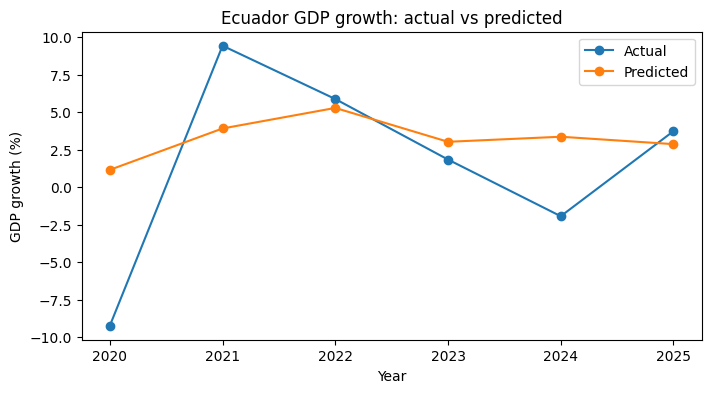

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(y_test.index, y_test.values, marker="o", label="Actual")
plt.plot(y_test.index, best_predictions, marker="o", label="Predicted")
plt.title("Ecuador GDP growth: actual vs predicted")
plt.xlabel("Year")
plt.ylabel("GDP growth (%)")
plt.legend()
plt.show()

My dataset has 31 years of information. I trained the model with 1995–2019 and tested it with 2020–2025. The final model had a test MAE of about 3.97 percentage points and an R² of about 0.21. The average cross-validation MAE was about 2.83 percentage points. The model got some years closer than others, but it had problems with 2020 and 2021. I think the results are not very strong because I only have a small amount of yearly data. Also, I used indicators from the same year, so this is not a real forecast of future GDP growth.

# 4. Storytelling With Data plot

Reproduce any graph of your choice in chapter seven (p. 165-185) of the Storytelling With Data book as best you can. You do not have to get the exact data values right, just the overall look and feel.

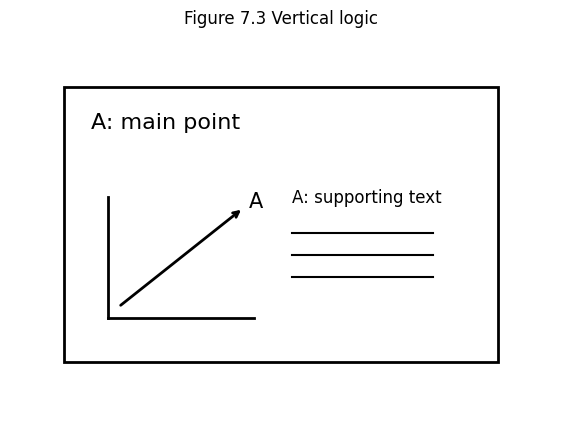

In [ ]:
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(7, 5))
ax.add_patch(Rectangle((1, 1), 8, 5, fill=False, edgecolor="black", linewidth=2))

ax.text(1.5, 5.25, "A: main point", fontsize=16)
ax.plot([1.8, 1.8], [1.8, 4], color="black", linewidth=2)
ax.plot([1.8, 4.5], [1.8, 1.8], color="black", linewidth=2)
ax.annotate("", xy=(4.3, 3.8), xytext=(2, 2),
            arrowprops={"arrowstyle": "->", "linewidth": 2})
ax.text(4.4, 3.8, "A", fontsize=15)

ax.text(5.2, 3.9, "A: supporting text", fontsize=12)
for y_line in [3.35, 2.95, 2.55]:
    ax.plot([5.2, 7.8], [y_line, y_line], color="black", linewidth=1.5)

ax.set_xlim(0, 10)
ax.set_ylim(0, 7)
ax.axis("off")
plt.title("Figure 7.3 Vertical logic")
plt.show()

I chose Figure 7.3 from Chapter 7. It shows a simple slide with a small graph and text. I recreated the general layout using Matplotlib. The drawing is not exact, but it has the same main idea.